In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, roc_auc_score,
                              roc_curve, classification_report)
import joblib

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42


## 1. Load data

In [2]:
df = pd.read_csv("data/water_potability.csv")
print(df.shape)
df.head()


(3276, 10)


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


## 2. Data quality checks

In [3]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


In [4]:
# Missing values
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct})


,missing_count,missing_pct
ph,491,14.99
Hardness,0,0.00
Solids,0,0.00
Chloramines,0,0.00
Sulfate,781,23.84
Conductivity,0,0.00
Organic_carbon,0,0.00
Trihalomethanes,162,4.95
Turbidity,0,0.00
Potability,0,0.00


In [5]:
# Duplicates
print("Duplicate rows:", df.duplicated().sum())

# Class balance
df["Potability"].value_counts(normalize=True).mul(100).round(1)


Duplicate rows: 0


Potability
0    61.0
1    39.0
Name: proportion, dtype: float64

## 3. Exploratory Data Analysis

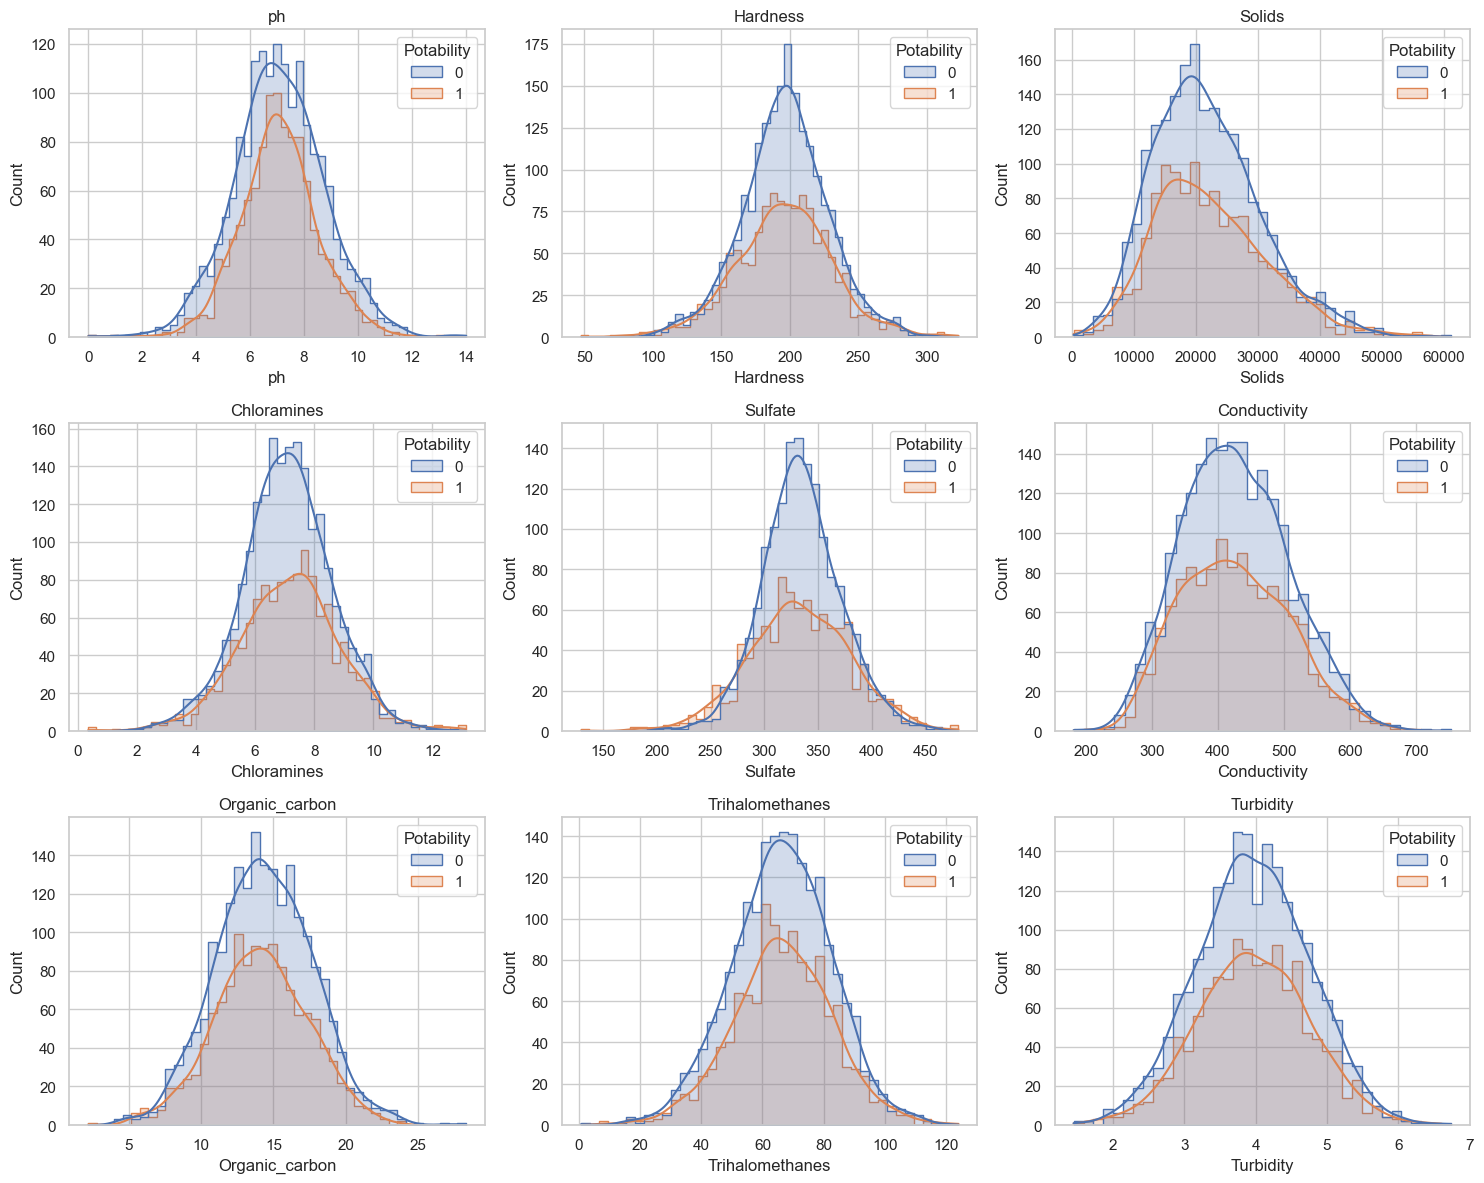

In [6]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
features = [c for c in df.columns if c != "Potability"]
for ax, col in zip(axes.flat, features):
    sns.histplot(data=df, x=col, hue="Potability", kde=True, ax=ax, element="step")
    ax.set_title(col)
plt.tight_layout()
plt.show()


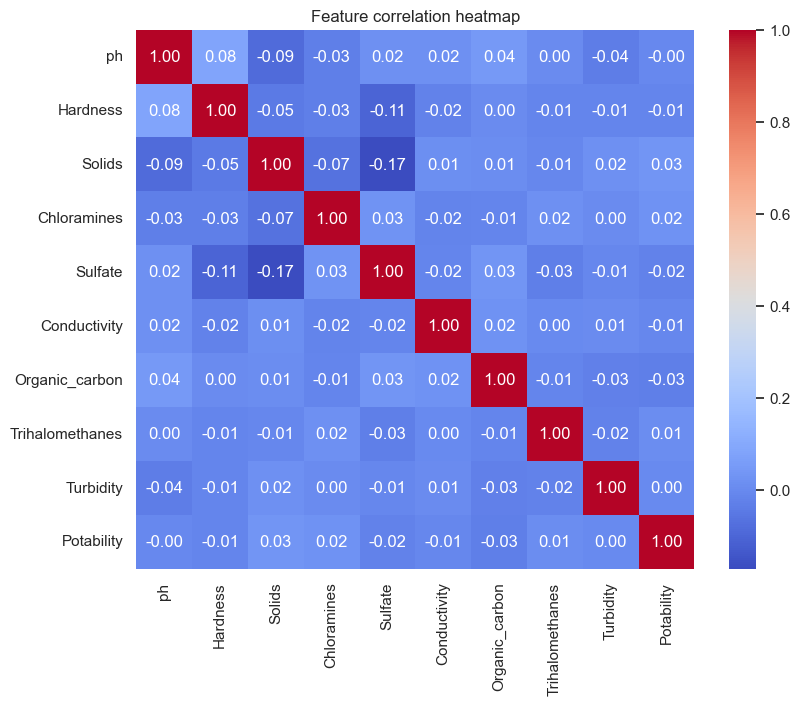

In [7]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Feature correlation heatmap")
plt.show()


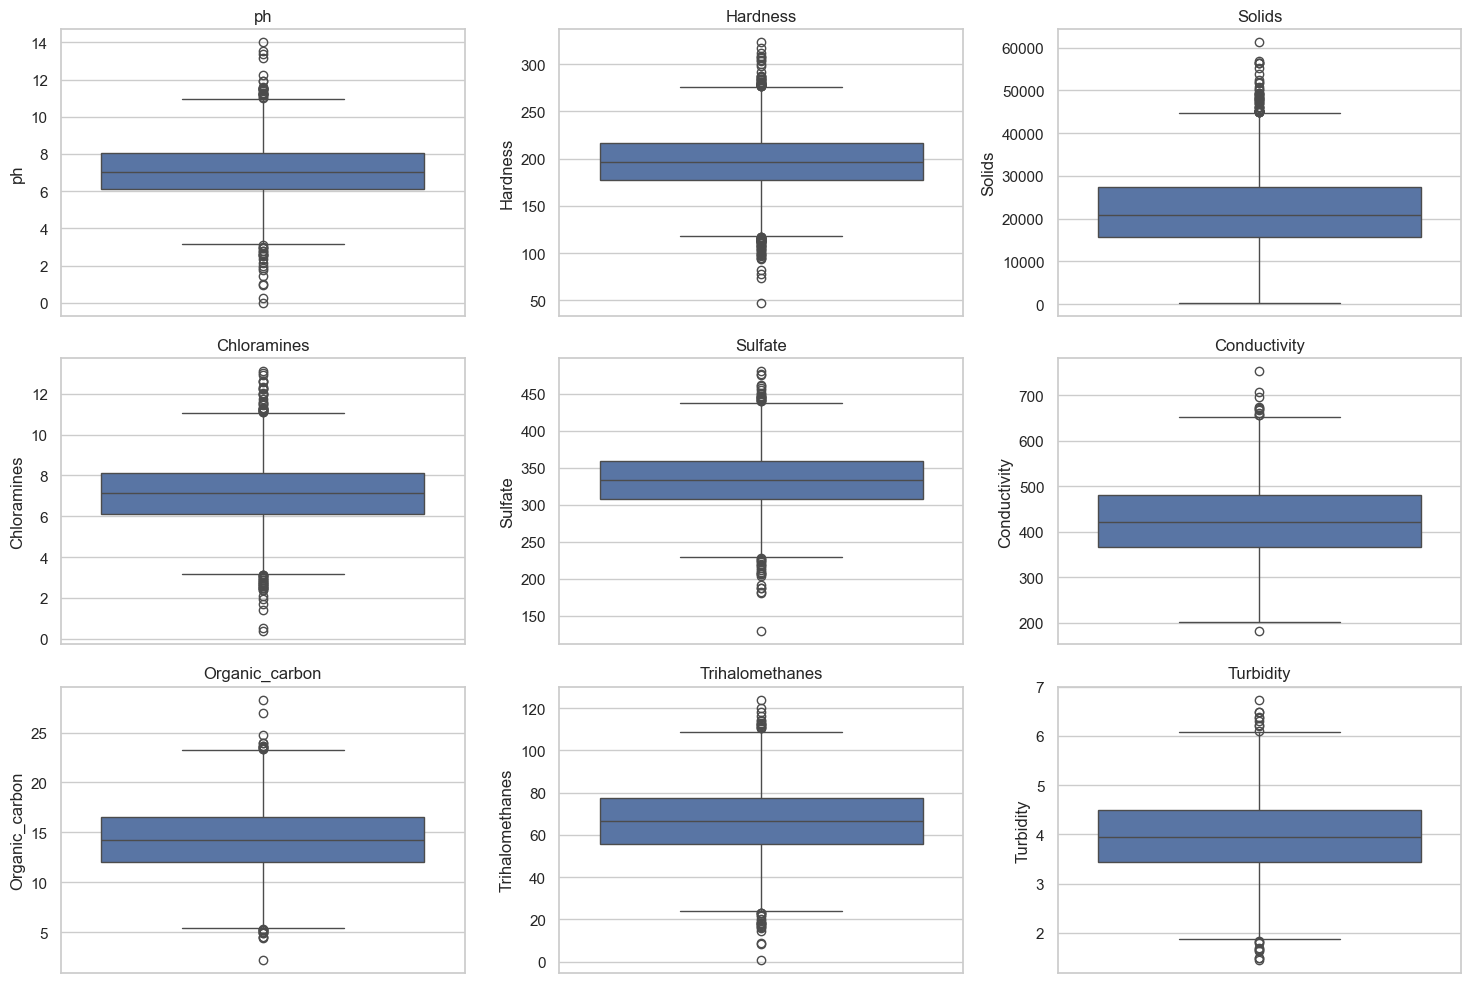

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, col in zip(axes.flat, features):
    sns.boxplot(data=df, y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()


**EDA notes to include in your paper:**
- Note which columns have missing values and roughly what % (pH, Sulfate, Trihalomethanes typically).
- Note whether classes are balanced or not (usually ~61% not potable / 39% potable).
- Note that most individual features show weak/overlapping distributions between the two classes —
  this is a genuine, honest finding to report, not a flaw in your work.


## 4. Preprocessing

In [9]:
X = df[features].copy()
y = df["Potability"].copy()

# Median imputation per column (fit only on train to avoid leakage)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

medians = X_train.median()
X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)  # use train medians on test -> no leakage

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(X_train.shape, X_test.shape)


(2620, 9) (656, 9)


## 5. Model training — compare foundational models

In [10]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=9),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, random_state=RANDOM_STATE),
}

results = []
fitted_models = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)
    proba = model.predict_proba(X_test_scaled)[:, 1]

    results.append({
        "model": name,
        "accuracy": accuracy_score(y_test, preds),
        "precision": precision_score(y_test, preds),
        "recall": recall_score(y_test, preds),
        "f1": f1_score(y_test, preds),
        "roc_auc": roc_auc_score(y_test, proba),
    })
    fitted_models[name] = model

results_df = pd.DataFrame(results).set_index("model").round(3)
results_df


C:\Users\geeth\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,accuracy,precision,recall,f1,roc_auc
model,,,,,
Logistic Regression,0.610,0.000,0.000,0.000,0.548
KNN,0.616,0.515,0.273,0.357,0.613
Decision Tree,0.642,0.595,0.258,0.360,0.608


## 6. Detailed evaluation of the best model

In [11]:
BEST_MODEL_NAME = results_df["f1"].idxmax()  # change manually if you prefer a different metric priority
print("Best model by F1:", BEST_MODEL_NAME)

best_model = fitted_models[BEST_MODEL_NAME]
preds = best_model.predict(X_test_scaled)
proba = best_model.predict_proba(X_test_scaled)[:, 1]

print(classification_report(y_test, preds))


Best model by F1: Decision Tree
              precision    recall  f1-score   support

           0       0.65      0.89      0.75       400
           1       0.59      0.26      0.36       256

    accuracy                           0.64       656
   macro avg       0.62      0.57      0.56       656
weighted avg       0.63      0.64      0.60       656



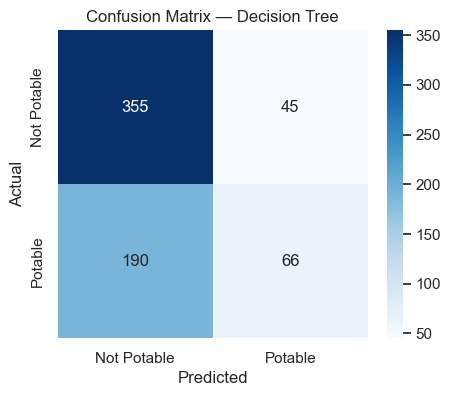

In [12]:
cm = confusion_matrix(y_test, preds)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Not Potable", "Potable"],
            yticklabels=["Not Potable", "Potable"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix — {BEST_MODEL_NAME}")
plt.show()


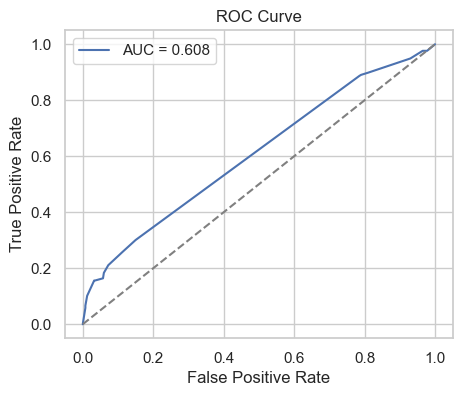

In [13]:
fpr, tpr, _ = roc_curve(y_test, proba)
plt.figure(figsize=(5, 4))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, proba):.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", color="grey")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()


**Interpretation prompts (answer these in your technical paper, not just report numbers):**
- Which matters more here, precision or recall? (Missing an unsafe sample = false negative — usually the costlier error for a safety task.)
- Does the model actually beat a "always predict majority class" baseline?
- Which features, if any, showed the strongest relationship with potability in the correlation heatmap?
- What's a plausible reason performance is capped (weak signal in features, small dataset, imputation choice)?


## 7. Save artifacts for the Streamlit app

In [14]:
joblib.dump(best_model, "model.joblib")
joblib.dump(scaler, "scaler.joblib")
joblib.dump(medians, "medians.joblib")
joblib.dump(features, "feature_order.joblib")
joblib.dump(BEST_MODEL_NAME, "model_name.joblib")

print("Saved: model.joblib, scaler.joblib, medians.joblib, feature_order.joblib")


Saved: model.joblib, scaler.joblib, medians.joblib, feature_order.joblib


In [15]:
df.sample(1, random_state=1)

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
136,6.063355,160.767311,14775.145596,7.484104,305.828553,327.270239,12.309016,69.038454,3.467337,0
